In [ ]:
pip install pretty_midi

In [ ]:
import pretty_midi
import numpy as np
file_name_string = "Prelude-in-E-Minor-Nr-4.mid"
midi = pretty_midi.PrettyMIDI(file_name_string)

pitches = set()

for instrument in midi.instruments:
    for note in instrument.notes:
        pitches.add(note.pitch)

In [ ]:
def midi_to_binary_matrix(
    midi_input,
    dt=0.02,                     # time quantum in seconds
    pitch_range=(21, 108),  # A0–C8 by default
    min_overlap=0.5         # fraction of frame that must be covered
):
    """
    Convert MIDI to binary (88 x T) note activation matrix using fixed time grid.

    A note is active in a frame if it overlaps the frame
    by at least min_overlap * dt.
    """

    if dt <= 0:
        raise ValueError("dt must be positive (seconds)")

    # Load MIDI
    if isinstance(midi_input, pretty_midi.PrettyMIDI):
        pm = midi_input
    else:
        pm = pretty_midi.PrettyMIDI(midi_input)

    # Time axis
    total_time = pm.get_end_time()
    T = int(np.ceil(total_time / dt))
    frame_times = np.arange(T) * dt

    n_pitches = pitch_range[1] - pitch_range[0] + 1
    B = np.zeros((n_pitches, T), dtype=np.uint8)

    # Process notes
    for instrument in pm.instruments:
        if instrument.is_drum:
            continue

        for note in instrument.notes:
            if not (pitch_range[0] <= note.pitch <= pitch_range[1]):
                continue

            p = note.pitch - pitch_range[0]

            start_frame = int(np.floor(note.start / dt))
            end_frame   = int(np.ceil(note.end   / dt))

            for t in range(start_frame, min(end_frame, T)):
                frame_start = t * dt
                frame_end   = frame_start + dt

                overlap = max(
                    0.0,
                    min(note.end, frame_end) - max(note.start, frame_start)
                )

                if overlap >= min_overlap * dt:
                    B[p, t] = 1

    return B, frame_times
def compute_pol_index(B):
  #1st result - polyphony index
  #2nd result - % of monophonic frames
  s = 0
  k = 0
  l = 0
  v = 0
  d = 0
  #print(B.shape[1])
  for i in range(B.shape[1]):
    m = np.count_nonzero(B[:,i])
    if(m>0):
      if(m==1):
        v += 1
      else:
        d += m
        l += 1
      s += m
      k += 1
  s = s / k
  v = v / k
  d = d / l
  return (s,v,d)

(2.490253987005316, 0.47607796810395747, 3.8444193912063134)


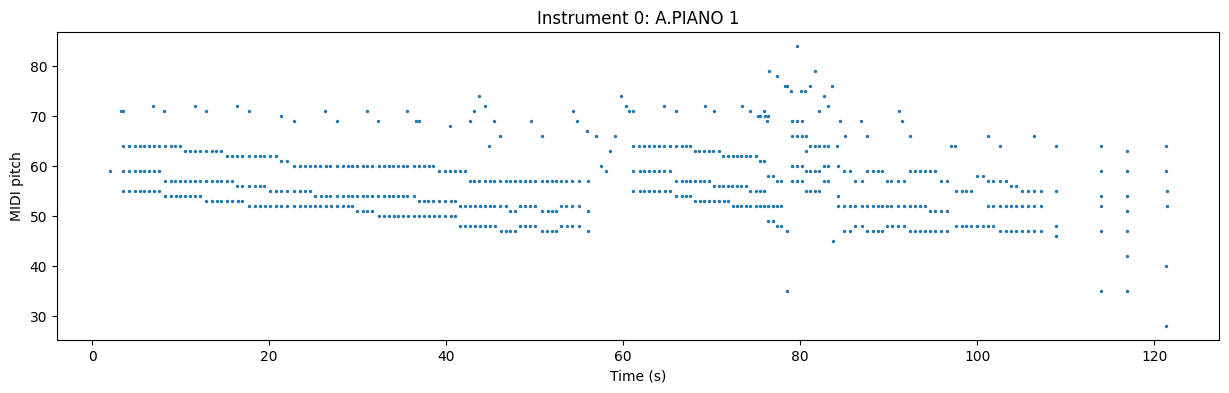

In [ ]:
import matplotlib.pyplot as plt
f_s = 44100
dt = 1024 / f_s
B, times = midi_to_binary_matrix(
    file_name_string,
    dt=dt
)
print(compute_pol_index(B))
pm = pretty_midi.PrettyMIDI(file_name_string)
for i, instrument in enumerate(pm.instruments):
    if instrument.is_drum:
        continue

    pitches = [n.pitch for n in instrument.notes]
    times = [n.start for n in instrument.notes]

    plt.figure(figsize=(15, 4))
    plt.scatter(times, pitches, s=2)
    plt.title(f"Instrument {i}: {instrument.name}")
    plt.xlabel("Time (s)")
    plt.ylabel("MIDI pitch")
    plt.show()

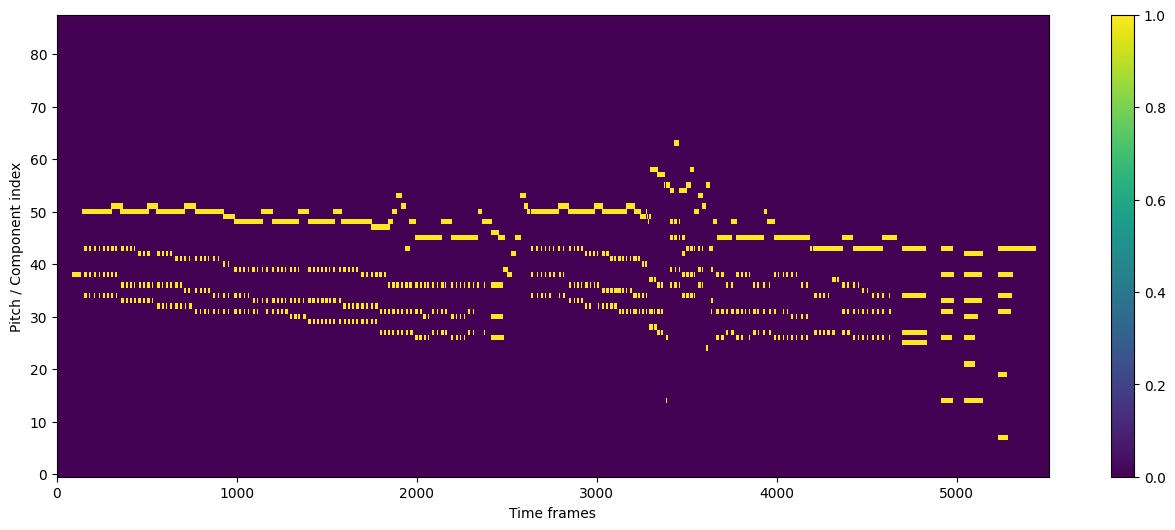

In [ ]:
plt.figure(figsize=(16, 6))

plt.imshow(
    B,
    aspect="auto",
    origin="lower",
    interpolation="none",
    cmap="viridis"
)

plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.colorbar()
plt.show()

Text(0, 0.5, 'Pitch index')

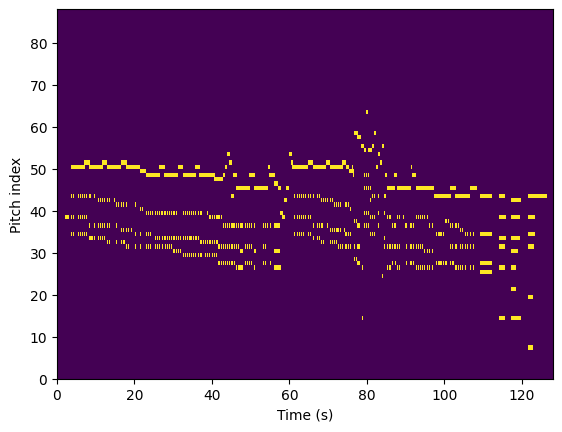

In [ ]:
T = B.shape[1]
frame_times = np.arange(T) * dt
plt.imshow(
    B,
    aspect="auto",
    origin="lower",
    interpolation="none",
    extent=[0, T * dt, 0, 88],
    cmap="viridis"
)

plt.xlabel("Time (s)")
plt.ylabel("Pitch index")

In [ ]:
import math
def compute_B(p):
    B_ref = 4e-4
    B_min = 1e-4
    B_max = 1e-2
    p_ref = 69

    kappa = np.log(B_max / B_ref) / (108 - p_ref)

    B = B_ref * np.exp(kappa * (np.asarray(p) - p_ref))

    return np.clip(B, B_min, B_max)
def freq(p,K):
  return 440 * 2**((p*K-49*K)/(12*K))
def freq_compute(p,h):
  return h*freq(p,K)*math.sqrt((1+compute_B(p/K)*h**2)/(1+compute_B(p/K)))

In [ ]:
print(freq_compute(49,10))

3
4421.72419261044


/tmp/ipykernel_5340/34552176.py:8: WavFileWarning: Reached EOF prematurely; finished at 15728640 bytes, expected 22780972 bytes from header.
  f_s, x = wavfile.read(file_name_string_audio)


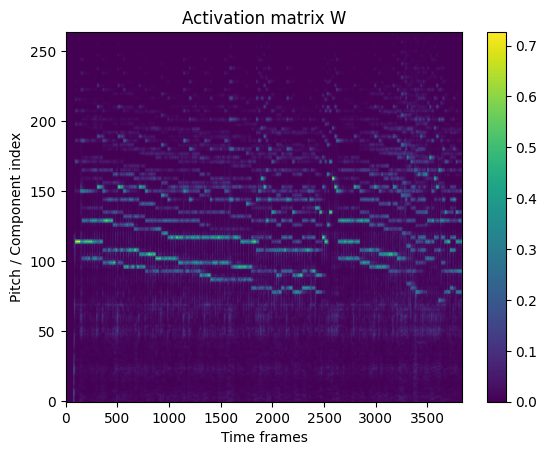

In [ ]:
from scipy.io import wavfile
import librosa
import numpy as np
K = 3
HOP = 1024
file_name_string_audio = "Prelude-in-E-Minor-Nr-4.wav"
g = 2
f_s, x = wavfile.read(file_name_string_audio)
if(x.dtype==np.int32):
  x = x / (2**31)
elif(x.dtype==np.int16):
  x = x / (2**15)
else:
  raise ValueError(f"Unsupported sample type: {x.dtype}")
spectrogram = np.abs(librosa.cqt(x,sr=f_s, fmin=librosa.note_to_hz('A0'), bins_per_octave=12 * K, n_bins=88 * K, hop_length=HOP))
K = 3
def norm_log(H, gamma=5):
    return np.log1p(gamma * H)
spectrogram = norm_log(spectrogram, g)
spectrogram = librosa.util.normalize(spectrogram, norm = 2, axis = 0, threshold = 0.05)

import matplotlib.pyplot as plt
plt.figure()
plt.imshow(spectrogram, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [2]:
import numpy as np

def compute_B(midi_pitch):
    B_ref = 4e-4
    B_min = 1e-4
    B_max = 1e-2
    p_ref = 69

    kappa = np.log(B_max / B_ref) / (108 - p_ref)

    B = B_ref * np.exp(kappa * (np.asarray(midi_pitch) - p_ref))

    return np.clip(B, B_min, B_max)


def freq(p):
    """p=1 -> A0; p=49 -> A4; p=88 -> C8."""
    return 440.0 * 2.0 ** ((p - 49) / 12.0)


def freq_compute(p, h):
    """Frequency of harmonic h of piano key p."""
    B = float(compute_B(p + 20))
    f0 = freq(p)

    return h * f0 * np.sqrt(
        (1.0 + B * h**2) / (1.0 + B)
    )


def compute_S_p(
    cqt_frame,
    cqt_freqs,
    p,
    K,
    max_harmonics=12,
    sigma_bins=0.75,
    gamma=1.0,
    power_input=False,
):
    """
    Harmonic salience for one piano key in one CQT frame.

    Parameters
    ----------
    cqt_frame:
        One column of the CQT matrix; complex coefficients
        or magnitudes, unless power_input=True.
    cqt_freqs:
        Actual CQT center frequencies in Hz.
    p:
        1-based piano-key index (1=A0, 49=A4, 88=C8).
    K:
        CQT resolution: bins_per_octave = 12*K.
    max_harmonics:
        Maximum harmonic number.
    sigma_bins:
        Gaussian neighborhood width in CQT bins.
    gamma:
        Harmonic weights are 1 / h**gamma.
    power_input:
        Set True if cqt_frame already contains power.

    Returns
    -------
    float
        Background-subtracted harmonic salience.
    """
    frame = np.asarray(cqt_frame)
    freqs = np.asarray(cqt_freqs, dtype=float)

    if not 1 <= p <= 88:
        raise ValueError("p must be between 1 and 88")

    if K <= 0 or sigma_bins <= 0:
        raise ValueError("K and sigma_bins must be positive")

    if frame.ndim != 1 or freqs.ndim != 1:
        raise ValueError("Inputs must be one-dimensional")

    if len(frame) != len(freqs):
        raise ValueError("cqt_frame and cqt_freqs must have equal lengths")

    if np.any(freqs <= 0) or np.any(np.diff(freqs) <= 0):
        raise ValueError("cqt_freqs must be positive and increasing")

    power = (
        np.asarray(frame, dtype=float)
        if power_input
        else np.abs(frame) ** 2
    )

    if np.any(power < 0) or not np.all(np.isfinite(power)):
        raise ValueError("Power must be finite and non-negative")

    numerator = 0.0
    norm_sq = 0.0

    for h in range(1, max_harmonics + 1):
        f_h = float(freq_compute(p, h))

        # The spectrum ends above the highest represented frequency.
        if f_h > freqs[-1]:
            break

        if f_h < freqs[0]:
            continue

        # Log-frequency distance, measured in CQT bins.
        distance = 12.0 * K * np.log2(freqs / f_h)
        abs_distance = np.abs(distance)

        # Local neighborhood around the expected harmonic.
        local_mask = abs_distance <= 3.0 * sigma_bins

        if not np.any(local_mask):
            continue

        gaussian = np.exp(
            -0.5 * (distance[local_mask] / sigma_bins) ** 2
        )

        local_power = np.sum(
            gaussian * power[local_mask]
        ) / np.sum(gaussian)

        # Estimate background from bins farther away from the peak.
        background_mask = (
            (abs_distance >= 3.0)
            & (abs_distance <= 6.0)
        )

        if np.any(background_mask):
            background = np.median(power[background_mask])
        else:
            background = 0.0

        contrast = max(local_power - background, 0.0)

        weight = 1.0 / (h ** gamma)

        numerator += weight * contrast
        norm_sq += weight**2

    if norm_sq == 0:
        return 0.0

    return float(numerator / np.sqrt(norm_sq))

In [ ]:
import librosa
import numpy as np

K = 3
fmin = librosa.note_to_hz("A0")

# Example CQT calculation
# C = librosa.cqt(
#     y,
#     sr=sr,
#     fmin=fmin,
#     bins_per_octave=12 * K,
#     n_bins=88 * K,
#     hop_length=512,
# )

cqt_freqs = librosa.cqt_frequencies(
    n_bins=spectrogram.shape[0],
    fmin=fmin,
    bins_per_octave=12 * K,
)

frame_idx = 112
cqt_frame = spectrogram[:, frame_idx]

# A4, i.e. piano key index p=49
sa = []
for l in range(1,89):
  S = compute_S_p(
      cqt_frame=cqt_frame,
      cqt_freqs=cqt_freqs,
      p=l,
      K=K,
      max_harmonics=12,
      sigma_bins=0.75,
      gamma=5.0,
      #return_details=True,
  )
  sa.append(S)
  #print("l = ", l)
  #print("S_p =", S)

In [ ]:
# A4, i.e. piano key index p=49
from tqdm.auto import tqdm

progress = tqdm(range(spectrogram.shape[1]), desc="NMF")

SM = np.zeros((88,spectrogram.shape[1]))
#for frame_idx in range(spectrogram.shape[1]):
for iteration in progress:
  cqt_frame = spectrogram[:, frame_idx]
  sa = []
  for l in range(1,89):
    S = compute_S_p(
        cqt_frame=cqt_frame,
        cqt_freqs=cqt_freqs,
        p=l,
        K=K,
        max_harmonics=12,
        sigma_bins=0.75,
        gamma=5.0,
        #return_details=True,
    )
    sa.append(S)
  #print(sa)
  #print(frame_idx)
  SM[:,frame_idx] = sa
  #progress.set_postfix(frame_idx=f"{frame_idx:.6f}")
#import matplotlib.pyplot as plt
#m = max(sa)
#sn = [x/m for x in sa]
plt.plot(sn, marker='o')
plt.plot(B[:,frame_idx], marker='x')
plt.xlabel("Index")
plt.ylabel("Value")
plt.title("My graph")
plt.grid(True)
plt.show()

NMF:   0%|          | 0/5562 [00:00<?, ?it/s]

KeyboardInterrupt: 

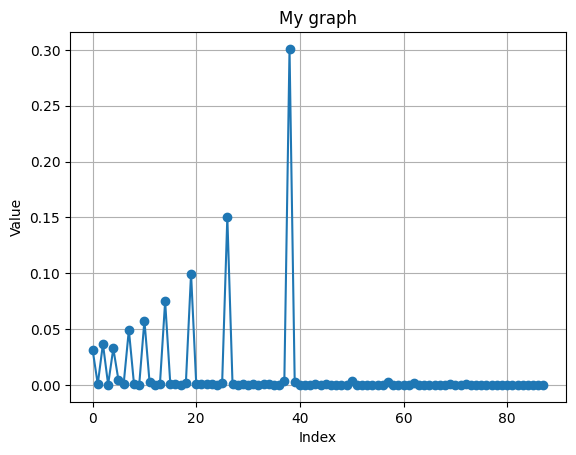

In [ ]:
import matplotlib.pyplot as plt

plt.plot(sa, marker='o')
plt.xlabel("Index")
plt.ylabel("Value")
plt.title("My graph")
plt.grid(True)
plt.show()

Computing salience:   0%|          | 0/22 [00:00<?, ?it/s]

(88, 5562)


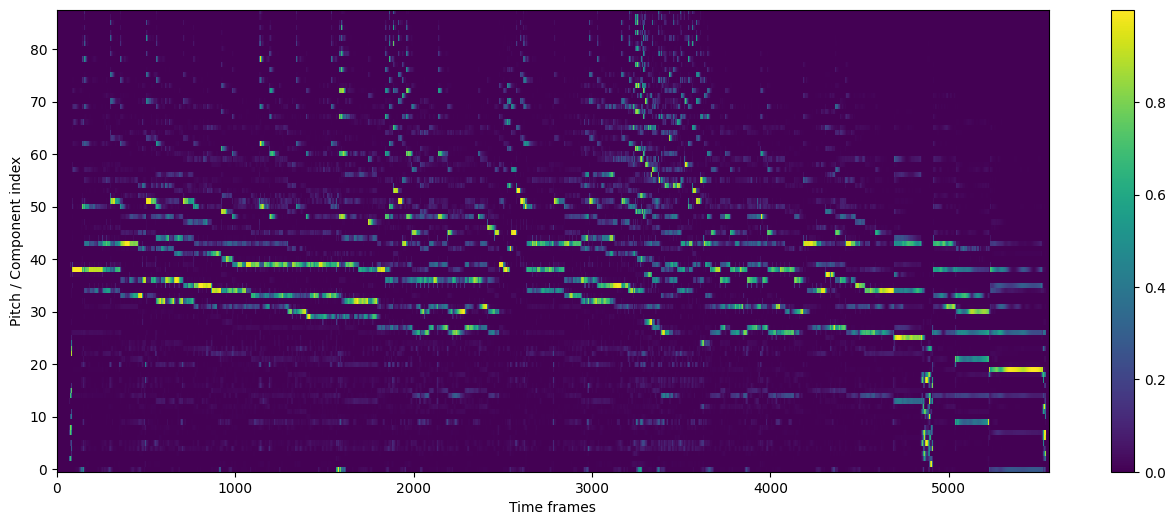

In [ ]:
%pip install numba
import numpy as np
from numba import njit
from tqdm.auto import tqdm
from scipy.ndimage import label

def _piano_harmonic_frequency(p, h):
    """p=1 -> A0, p=49 -> A4; h is the harmonic number."""
    midi_pitch = p + 20

    B_ref = 4e-4
    B_min = 1e-4
    B_max = 1e-2
    p_ref = 69

    kappa = np.log(B_max / B_ref) / (108 - p_ref)
    B = np.clip(
        B_ref * np.exp(kappa * (midi_pitch - p_ref)),
        B_min,
        B_max,
    )

    f0 = 440.0 * 2.0 ** ((p - 49) / 12.0)

    return h * f0 * np.sqrt((1.0 + B * h**2) / (1.0 + B))


def precompute_salience_kernels(
    cqt_freqs,
    K,
    max_harmonics=12,
    sigma_bins=0.75,
    gamma=5.0,
):
    """
    Precompute local Gaussian weights and background-bin indices
    for every piano key and harmonic.
    """
    freqs = np.asarray(cqt_freqs, dtype=np.float64)
    F = len(freqs)

    # Temporary storage for each (pitch, harmonic).
    terms = [[None] * max_harmonics for _ in range(88)]

    max_local = 1
    max_background = 1

    for pi, p in enumerate(range(1, 89)):
        for h in range(1, max_harmonics + 1):
            f_h = _piano_harmonic_frequency(p, h)

            if f_h > freqs[-1]:
                break
            if f_h < freqs[0]:
                continue

            # Distance measured in logarithmic CQT bins.
            distance = 12.0 * K * np.log2(freqs / f_h)
            abs_distance = np.abs(distance)

            local_idx = np.flatnonzero(
                abs_distance <= 3.0 * sigma_bins
            )

            if local_idx.size == 0:
                continue

            local_weights = np.exp(
                -0.5 * (
                    distance[local_idx] / sigma_bins
                ) ** 2
            )

            background_idx = np.flatnonzero(
                (abs_distance >= 3.0)
                & (abs_distance <= 6.0)
            )

            harmonic_weight = 1.0 / (h ** gamma)

            terms[pi][h - 1] = (
                local_idx,
                local_weights,
                background_idx,
                harmonic_weight,
            )

            max_local = max(max_local, len(local_idx))
            max_background = max(
                max_background, len(background_idx)
            )

    # Padded arrays allow Numba to process all pitches efficiently.
    shape = (88, max_harmonics)

    local_idx = np.zeros(
        (*shape, max_local), dtype=np.int32
    )
    local_weights = np.zeros(
        (*shape, max_local), dtype=np.float64
    )
    local_counts = np.zeros(shape, dtype=np.int32)
    local_weight_sums = np.zeros(shape, dtype=np.float64)

    background_idx = np.zeros(
        (*shape, max_background), dtype=np.int32
    )
    background_counts = np.zeros(shape, dtype=np.int32)

    harmonic_weights = np.zeros(shape, dtype=np.float64)

    for pi in range(88):
        for hi in range(max_harmonics):
            term = terms[pi][hi]

            if term is None:
                continue

            li, lw, bi, hw = term

            nl = len(li)
            nb = len(bi)

            local_idx[pi, hi, :nl] = li
            local_weights[pi, hi, :nl] = lw
            local_counts[pi, hi] = nl
            local_weight_sums[pi, hi] = lw.sum()

            if nb > 0:
                background_idx[pi, hi, :nb] = bi
                background_counts[pi, hi] = nb

            harmonic_weights[pi, hi] = hw

    # This matches the normalization in compute_S_p.
    norms = np.sqrt(np.sum(harmonic_weights**2, axis=1))

    return (
        local_idx,
        local_weights,
        local_counts,
        local_weight_sums,
        background_idx,
        background_counts,
        harmonic_weights,
        norms,
    )
@njit
def _salience_batch_numba(
    power_batch,
    local_idx,
    local_weights,
    local_counts,
    local_weight_sums,
    background_idx,
    background_counts,
    harmonic_weights,
    norms,
):
    """
    power_batch has shape (number_of_frames, number_of_bins).
    Returns salience with shape (number_of_frames, 88).
    """
    n_frames = power_batch.shape[0]
    n_harmonics = local_counts.shape[1]
    max_background = background_idx.shape[2]

    result = np.zeros((n_frames, 88), dtype=np.float64)
    scratch = np.empty(max_background, dtype=np.float64)

    for t in range(n_frames):
        frame = power_batch[t]

        for pi in range(88):
            numerator = 0.0

            for hi in range(n_harmonics):
                nl = local_counts[pi, hi]

                if nl == 0:
                    continue

                # Gaussian-weighted local power.
                local_power = 0.0

                for j in range(nl):
                    k = local_idx[pi, hi, j]
                    local_power += (
                        local_weights[pi, hi, j] * frame[k]
                    )

                local_power /= local_weight_sums[pi, hi]

                # Local median background.
                nb = background_counts[pi, hi]
                background = 0.0

                if nb > 0:
                    for j in range(nb):
                        k = background_idx[pi, hi, j]
                        scratch[j] = frame[k]

                    # In-place insertion sort; neighborhoods are small.
                    for j in range(1, nb):
                        value = scratch[j]
                        q = j - 1

                        while q >= 0 and scratch[q] > value:
                            scratch[q + 1] = scratch[q]
                            q -= 1

                        scratch[q + 1] = value

                    if nb % 2 == 1:
                        background = scratch[nb // 2]
                    else:
                        background = 0.5 * (
                            scratch[nb // 2 - 1]
                            + scratch[nb // 2]
                        )

                contrast = local_power - background

                if contrast > 0.0:
                    numerator += (
                        harmonic_weights[pi, hi] * contrast
                    )

            if norms[pi] > 0.0:
                result[t, pi] = numerator / norms[pi]

    return result
def compute_salience_matrix_fast(
    spectrogram,
    cqt_freqs,
    K,
    max_harmonics=12,
    sigma_bins=0.75,
    gamma=5.0,
    batch_size=256,
    input_is_power=False,
):
    """
    Parameters
    ----------
    spectrogram : array, shape (frequency_bins, time_frames)
        Complex CQT coefficients or linear CQT magnitudes.
        If input_is_power=True, pass power values instead.

    Returns
    -------
    SM : array, shape (88, time_frames)
        SM[p-1, t] is the salience of piano key p in frame t.
    """
    X = np.asarray(spectrogram)

    if X.ndim != 2:
        raise ValueError("spectrogram must be a 2-D array")

    if X.shape[0] != len(cqt_freqs):
        raise ValueError(
            "The number of spectrogram rows must match cqt_freqs"
        )

    if input_is_power:
        power = np.asarray(X.T, dtype=np.float64)
    else:
        power = np.asarray(np.abs(X.T) ** 2, dtype=np.float64)

    if not np.all(np.isfinite(power)) or np.any(power < 0):
        raise ValueError("Spectrogram power must be finite and non-negative")

    power = np.ascontiguousarray(power)

    kernels = precompute_salience_kernels(
        cqt_freqs=cqt_freqs,
        K=K,
        max_harmonics=max_harmonics,
        sigma_bins=sigma_bins,
        gamma=gamma,
    )

    (
        local_idx,
        local_weights,
        local_counts,
        local_weight_sums,
        background_idx,
        background_counts,
        harmonic_weights,
        norms,
    ) = kernels

    n_frames = power.shape[0]
    SM = np.empty((88, n_frames), dtype=np.float64)

    # Trigger compilation before starting the progress bar.
    # The first Numba call compiles the numerical kernel.
    if n_frames > 0:
        _salience_batch_numba(
            power[:1],
            local_idx,
            local_weights,
            local_counts,
            local_weight_sums,
            background_idx,
            background_counts,
            harmonic_weights,
            norms,
        )

    for start in tqdm(
        range(0, n_frames, batch_size),
        desc="Computing salience",
    ):
        stop = min(start + batch_size, n_frames)

        batch_result = _salience_batch_numba(
            power[start:stop],
            local_idx,
            local_weights,
            local_counts,
            local_weight_sums,
            background_idx,
            background_counts,
            harmonic_weights,
            norms,
        )

        SM[:, start:stop] = batch_result.T

    return SM
SM = compute_salience_matrix_fast(
    spectrogram=spectrogram,
    cqt_freqs=cqt_freqs,
    K=K,
    max_harmonics=12,
    sigma_bins=0.75,
    gamma=5.0,
    batch_size=256,
)

print(SM.shape)

#import matplotlib.pyplot as plt
#m = max(sa)
#sn = [x/m for x in sa]
def rowwise_norm(H, eps=1e-8):
    Hn = H.copy()
    for q in range(H.shape[0]):
        m = np.max(Hn[q])
        if m > eps:
            Hn[q] /= m
    return Hn
def enforce_min_duration(B, min_len=10):
    for q in range(B.shape[0]):
        labels, n = label(B[q])
        for i in range(1, n+1):
            if np.sum(labels == i) < min_len:
                B[q][labels == i] = 0
    return B
def matrix_filter(H):
  H_c = H.copy()
  for i in range(H_c.shape[0]):
    for j in range(H_c.shape[1]):
      v = 0
      if ((j-1)>=0):
        v += H_c[i,j-1]
      if((j+1)<H_c.shape[1]):
        v += H_c[i,j+1]
      v += H_c[i,j]
      v = v / 3
      H_c[i,j] = v
  return H_c
SMF = norm_log(SM, g)
SM = librosa.util.normalize(SM, norm = 2, axis = 0, threshold = 0.05)
SM = rowwise_norm(SM)
SM = matrix_filter(SM)
SM = enforce_min_duration(SM)
'''import matplotlib.pyplot as plt
plt.figure()
plt.imshow(SM, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()'''
plt.figure(figsize=(16, 6))

plt.imshow(
    SM,
    aspect="auto",
    origin="lower",
    interpolation="none",
    cmap="viridis"
)

plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.colorbar()
plt.show()
# (88, 5562)

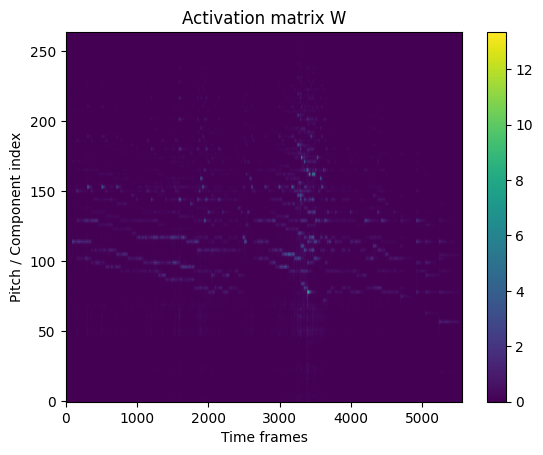

In [3]:
from scipy.io import wavfile
import librosa
import numpy as np
K = 3
HOP = 1024
file_name_string_audio = "Prelude-in-E-Minor-Nr-4.wav"
g = 2
f_s, x = wavfile.read(file_name_string_audio)
if(x.dtype==np.int32):
  x = x / (2**31)
elif(x.dtype==np.int16):
  x = x / (2**15)
else:
  raise ValueError(f"Unsupported sample type: {x.dtype}")
spectrogram = np.abs(librosa.cqt(x,sr=f_s, fmin=librosa.note_to_hz('A0'), bins_per_octave=12 * K, n_bins=88 * K, hop_length=HOP))
K = 3

import matplotlib.pyplot as plt
plt.figure()
plt.imshow(spectrogram, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [ ]:
from scipy.ndimage import label
from scipy import signal
g=2
def norm_log(H, gamma=5):
    return np.log1p(gamma * H)
def rowwise_norm(H, eps=1e-8):
    Hn = H.copy()
    for q in range(H.shape[0]):
        m = np.max(Hn[q])
        if m > eps:
            Hn[q] /= m
    return Hn
def enforce_min_duration(B, min_len=10):
    for q in range(B.shape[0]):
        labels, n = label(B[q])
        for i in range(1, n+1):
            if np.sum(labels == i) < min_len:
                B[q][labels == i] = 0
    return B
def matrix_filter(H):
  H_c = H.copy()
  for i in range(H_c.shape[0]):
    for j in range(H_c.shape[1]):
      v = 0
      if ((j-1)>=0):
        v += H_c[i,j-1]
      if((j+1)<H_c.shape[1]):
        v += H_c[i,j+1]
      v += H_c[i,j]
      v = v / 3
      H_c[i,j] = v
  return H_c
def compress(l):
  r = np.zeros((88))
  for i in range(1,89):
    r[i-1] = l[]
SM = norm_log(spectrogram, g)
SM = librosa.util.normalize(SM, norm = 2, axis = 0, threshold = 0.05)
SM = rowwise_norm(SM)
SM = matrix_filter(SM)
SM = enforce_min_duration(SM)
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(SM, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix H")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

SyntaxError: invalid syntax (962157759.py, line 36)

In [165]:
from __future__ import annotations

from dataclasses import dataclass
from typing import Optional, Sequence

import numpy as np


@dataclass
class NMFHistory:
    objective: list[float]
    reconstruction: list[float]
    sparsity: list[float]
    volume: list[float]
    separability: list[float]


class MinimumVolumeSparseNearSeparableNMF:
    """
    Minimum-Volume Sparse Near-Separable NMF.

    Solves approximately:

        min_{W,H >= 0}
            0.5 ||X - WH||_F^2
            + lambda_h ||H||_1
            + 0.5 * lambda_v * log det(
                  W^T W + 1 1^T + delta I
              )
            + lambda_s * sum_k min_a ||w_k - xhat_a||_2^2

        subject to:
            sum_f W[f, k] = 1  for every k.

    Parameters
    ----------
    rank:
        Number of components.

    lambda_h:
        Sparsity regularization on H.

    lambda_v:
        Minimum-volume regularization on W.

    lambda_s:
        Near-separability regularization on W.

    delta:
        Small positive stabilization constant in the log-det term.

    max_iter:
        Number of outer alternating iterations.

    h_inner_iter:
        Number of HALS sweeps for H per outer iteration.

    w_inner_iter:
        Number of projected-gradient steps for W per outer iteration.

    candidate_count:
        Number of anchor candidates used for near-separability.
        The actual number is min(candidate_count, T).

    anchor_update_period:
        Recompute nearest anchor assignments every N outer iterations.

    normalize_input:
        If True, divide X by its median positive column sum.
        This makes the scale of lambda_h considerably more interpretable.

    random_state:
        Random seed.

    tol:
        Relative objective convergence tolerance.

    verbose:
        Print progress.

    Notes
    -----
    This implementation is intentionally NumPy-based and does not require
    scipy/sklearn. For very large matrices, BLAS performance matters a lot.
    """

    def __init__(
        self,
        rank: int,
        lambda_h: float = 1e-2,
        lambda_v: float = 1e-2,
        lambda_s: float = 1e-2,
        delta: float = 1e-6,
        max_iter: int = 100,
        h_inner_iter: int = 2,
        w_inner_iter: int = 5,
        candidate_count: int = 512,
        anchor_update_period: int = 5,
        normalize_input: bool = True,
        random_state: Optional[int] = 0,
        tol: float = 1e-5,
        verbose: bool = True,
    ):
        if rank <= 0:
            raise ValueError("rank must be positive")

        '''if min(lambda_h, lambda_v, lambda_s) < 0:
            raise ValueError("Regularization parameters must be non-negative")'''

        if lambda_h < 0 or lambda_s < 0:
            raise ValueError("lambda_h and lambda_s must be non-negative")

        if delta <= 0:
            raise ValueError("delta must be > 0")

        self.rank = rank
        self.lambda_h = float(lambda_h)
        self.lambda_v = float(lambda_v)
        self.lambda_s = float(lambda_s)
        self.delta = float(delta)

        self.max_iter = max_iter
        self.h_inner_iter = h_inner_iter
        self.w_inner_iter = w_inner_iter

        self.candidate_count = candidate_count
        self.anchor_update_period = anchor_update_period

        self.normalize_input = normalize_input
        self.random_state = random_state

        self.tol = tol
        self.verbose = verbose

        self.W_: Optional[np.ndarray] = None
        self.H_: Optional[np.ndarray] = None

        self.X_scale_: float = 1.0
        self.anchor_indices_: Optional[np.ndarray] = None
        self.assigned_anchors_: Optional[np.ndarray] = None

        self.history_: Optional[NMFHistory] = None

    # ------------------------------------------------------------------
    # Utilities
    # ------------------------------------------------------------------

    @staticmethod
    def _check_X(X: np.ndarray) -> np.ndarray:
        X = np.asarray(X, dtype=np.float64)

        if X.ndim != 2:
            raise ValueError("X must be a 2-D array")

        if not np.all(np.isfinite(X)):
            raise ValueError("X contains NaN or infinite values")

        if np.any(X < 0):
            raise ValueError("NMF requires X >= 0")

        if np.all(X == 0):
            raise ValueError("X must not be identically zero")

        return X

    @staticmethod
    def _project_simplex_columns(V: np.ndarray) -> np.ndarray:
        """
        Euclidean projection of each column onto

            {x >= 0 : sum_i x_i = 1}.

        Vectorized implementation.
        """
        V = np.asarray(V, dtype=np.float64)

        U = np.sort(V, axis=0)[::-1]
        cssv = np.cumsum(U, axis=0)

        j = np.arange(1, V.shape[0] + 1, dtype=np.float64)[:, None]

        cond = U * j > (cssv - 1.0)

        rho = cond.sum(axis=0) - 1

        theta = (
            cssv[rho, np.arange(V.shape[1])] - 1.0
        ) / (rho + 1.0)

        return np.maximum(V - theta[None, :], 0.0)

    @staticmethod
    def _normalize_columns_l1(X: np.ndarray) -> np.ndarray:
        """
        Normalize columns to unit L1 norm.
        Zero columns remain zero.
        """
        sums = np.sum(X, axis=0)
        return X / np.maximum(sums[None, :], 1e-15)

    # ------------------------------------------------------------------
    # Anchor selection
    # ------------------------------------------------------------------

    def _select_anchor_candidates(
        self,
        X: np.ndarray,
    ) -> np.ndarray:
        """
        Select candidate frames.

        First rank frames by spectral concentration:

            ||x||_2 / ||x||_1

        and retain the most concentrated frames.

        This is only a heuristic. It is deliberately cheap.
        """
        X_norm = self._normalize_columns_l1(X)

        concentration = np.linalg.norm(X_norm, axis=0)

        T = X.shape[1]
        M = min(self.candidate_count, T)

        candidates = np.argpartition(
            concentration,
            -M
        )[-M:]

        # Deterministic ordering by concentration.
        candidates = candidates[
            np.argsort(concentration[candidates])[::-1]
        ]

        return candidates

    def _initialize_W(
        self,
        X: np.ndarray,
        candidates: np.ndarray,
        rng: np.random.Generator,
    ) -> np.ndarray:
        """
        Initialize W from candidate frames when possible.

        We choose diverse candidates using greedy farthest-point
        selection in normalized spectral space.
        """
        Xn = self._normalize_columns_l1(X)
        pool = Xn[:, candidates]

        M = pool.shape[1]

        if M < self.rank:
            raise ValueError(
                f"candidate_count={M} is smaller than rank={self.rank}"
            )

        # First component: most concentrated spectrum.
        selected = [0]

        min_dist = np.full(M, np.inf)

        for _ in range(1, self.rank):
            last = pool[:, selected[-1]]

            distances = np.sum(
                (pool - last[:, None]) ** 2,
                axis=0,
            )

            min_dist = np.minimum(min_dist, distances)

            min_dist[selected] = -np.inf

            next_idx = int(np.argmax(min_dist))
            selected.append(next_idx)

        W = pool[:, selected].copy()

        # Add a tiny amount of noise to avoid exact duplicate / degenerate
        # initial columns when candidate spectra are very similar.
        W += 1e-10 * rng.random(W.shape)

        return self._project_simplex_columns(W)

    def _initialize_H(
        self,
        X: np.ndarray,
        W: np.ndarray,
    ) -> np.ndarray:
        """
        Initial non-negative least-squares-like estimate.

        Uses the standard closed-form least-squares estimate followed
        by non-negativity projection.
        """
        gram = W.T @ W
        rhs = W.T @ X

        # Small stabilization.
        gram = gram + 1e-8 * np.eye(self.rank)

        try:
            H = np.linalg.solve(gram, rhs)
        except np.linalg.LinAlgError:
            H = np.linalg.pinv(gram) @ rhs

        H = np.maximum(H - self.lambda_h, 0.0)

        return H

    # ------------------------------------------------------------------
    # H update
    # ------------------------------------------------------------------

    def _update_H_hals(
        self,
        X: np.ndarray,
        W: np.ndarray,
        H: np.ndarray,
        R: np.ndarray,
    ) -> None:
        """
        Sparse HALS / coordinate descent.

        R is maintained as:

            R = X - W H

        in-place.
        """
        r = self.rank

        for _ in range(self.h_inner_iter):
            for k in range(r):
                w = W[:, k]

                # Add the old component back:
                #
                # R_k = X - sum_{j != k} w_j h_j
                h_old = H[k].copy()

                R_k = R + np.outer(w, h_old)

                numerator = w @ R_k - self.lambda_h
                denominator = w @ w

                if denominator <= 1e-15:
                    h_new = np.zeros_like(h_old)
                else:
                    h_new = np.maximum(
                        numerator / denominator,
                        0.0,
                    )

                H[k] = h_new

                # R_new = R_old - w (h_new - h_old)
                R -= np.outer(
                    w,
                    h_new - h_old,
                )

    # ------------------------------------------------------------------
    # Near-separability
    # ------------------------------------------------------------------

    def _update_anchor_assignments(
        self,
        W: np.ndarray,
        X: np.ndarray,
        candidate_indices: np.ndarray,
    ) -> np.ndarray:
        """
        For every W basis vector, select nearest normalized candidate:

            a_k = argmin_a ||w_k - xhat_a||^2.
        """
        X_candidates = self._normalize_columns_l1(
            X[:, candidate_indices]
        )

        # Since ||w - x||^2
        # = ||w||^2 + ||x||^2 - 2 w^T x
        #
        # this avoids constructing a rank x F x M tensor.
        W_norm_sq = np.sum(W * W, axis=0)[:, None]
        X_norm_sq = np.sum(
            X_candidates * X_candidates,
            axis=0,
        )[None, :]

        distances = (
            W_norm_sq
            + X_norm_sq
            - 2.0 * (W.T @ X_candidates)
        )

        nearest = np.argmin(distances, axis=1)

        return candidate_indices[nearest]

    # ------------------------------------------------------------------
    # W regularizers
    # ------------------------------------------------------------------

    def _volume_value_and_gradient(
        self,
        W: np.ndarray,
    ) -> tuple[float, np.ndarray]:
        """
        R_v(W) = 0.5 log det(
            W^T W + 11^T + delta I
        )

        because the augmented matrix is

            [ W ]
            [ 1^T ].

        Gradient:

            W A^{-1}
        """
        r = W.shape[1]

        ones = np.ones((r, 1))

        gram = (
            W.T @ W
            + ones @ ones.T
            + self.delta * np.eye(r)
        )

        sign, logdet = np.linalg.slogdet(gram)

        if sign <= 0:
            raise FloatingPointError(
                "Volume Gram matrix is not positive definite."
            )

        value = 0.5 * logdet

        try:
            inv_gram = np.linalg.solve(
                gram,
                np.eye(r),
            )
        except np.linalg.LinAlgError:
            inv_gram = np.linalg.pinv(gram)

        gradient = W @ inv_gram

        return value, gradient

    def _separability_value_and_gradient(
        self,
        W: np.ndarray,
        X: np.ndarray,
        anchor_indices: np.ndarray,
    ) -> tuple[float, np.ndarray]:
        """
        R_s(W) = sum_k ||w_k - xhat_{a_k}||^2
        """
        anchors = self._normalize_columns_l1(
            X[:, anchor_indices]
        )

        diff = W - anchors

        value = np.sum(diff * diff)

        gradient = 2.0 * diff

        return value, gradient

    # ------------------------------------------------------------------
    # Objective
    # ------------------------------------------------------------------

    def _objective(
        self,
        X: np.ndarray,
        W: np.ndarray,
        H: np.ndarray,
        anchor_indices: np.ndarray,
    ) -> tuple[float, float, float, float, float]:

        residual = X - W @ H

        reconstruction = 0.5 * np.sum(residual * residual)

        sparsity = np.sum(H)

        volume, _ = self._volume_value_and_gradient(W)

        separability, _ = self._separability_value_and_gradient(
            W,
            X,
            anchor_indices,
        )

        total = (
            reconstruction
            + self.lambda_h * sparsity
            + self.lambda_v * volume
            + self.lambda_s * separability
        )

        return (
            total,
            reconstruction,
            sparsity,
            volume,
            separability,
        )

    # ------------------------------------------------------------------
    # W update
    # ------------------------------------------------------------------

    def _update_W(
        self,
        X: np.ndarray,
        W: np.ndarray,
        H: np.ndarray,
        R: np.ndarray,
        anchor_indices: np.ndarray,
    ) -> np.ndarray:
        """
        Projected gradient update for W.

        The residual is:

            R = X - WH

        hence

            grad_fit = -R H^T.
        """
        WH = None  # intentionally unused; residual is supplied

        for _ in range(self.w_inner_iter):

            grad_fit = -(R @ H.T)

            volume_value, grad_volume = (
                self._volume_value_and_gradient(W)
            )

            sep_value, grad_sep = (
                self._separability_value_and_gradient(
                    W,
                    X,
                    anchor_indices,
                )
            )

            gradient = (
                grad_fit
                + self.lambda_v * grad_volume
                + self.lambda_s * grad_sep
            )

            # A practical Lipschitz estimate for the smooth fitting term.
            # The regularizer gradients are small matrices (F x r).
            HH = H @ H.T

            # largest eigenvalue of HH = Lipschitz constant
            # of the fitting gradient wrt W.
            try:
                L_fit = np.linalg.eigvalsh(HH)[-1]
            except np.linalg.LinAlgError:
                L_fit = np.linalg.norm(HH, 2)

            L_fit = max(float(L_fit), 1e-12)

            step = 1.0 / L_fit

            # Backtracking.
            old_W = W.copy()

            old_obj, *_ = self._objective(
                X,
                W,
                H,
                anchor_indices,
            )

            accepted = False

            for _bt in range(12):

                candidate = old_W - step * gradient

                candidate = self._project_simplex_columns(
                    candidate
                )

                new_obj, *_ = self._objective(
                    X,
                    candidate,
                    H,
                    anchor_indices,
                )

                if new_obj <= old_obj:
                    W = candidate
                    accepted = True
                    break

                step *= 0.5

            if not accepted:
                W = old_W
                break

            # Update residual incrementally:
            #
            # R_new = X - W_new H
            #       = R_old - (W_new - W_old) H
            #
            dW = W - old_W

            R -= dW @ H

        return W

    # ------------------------------------------------------------------
    # Fit
    # ------------------------------------------------------------------

    def fit(
        self,
        X: np.ndarray,
        W_init: Optional[np.ndarray] = None,
        H_init: Optional[np.ndarray] = None,
        anchor_indices: Optional[Sequence[int]] = None,
    ) -> "MinimumVolumeSparseNearSeparableNMF":

        X = self._check_X(X)

        F, T = X.shape

        if self.rank > min(F, T):
            raise ValueError(
                f"rank={self.rank} is larger than min(F,T)={min(F,T)}"
            )

        # --------------------------------------------------------------
        # Input scaling
        # --------------------------------------------------------------

        if self.normalize_input:
            column_sums = np.sum(X, axis=0)
            positive = column_sums[column_sums > 0]

            if positive.size == 0:
                raise ValueError("X contains no positive entries")

            scale = float(np.median(positive))

            if scale <= 0:
                scale = 1.0

            X_work = X / scale

            self.X_scale_ = scale

        else:
            X_work = X.copy()
            self.X_scale_ = 1.0

        # --------------------------------------------------------------
        # RNG
        # --------------------------------------------------------------

        rng = np.random.default_rng(self.random_state)

        # --------------------------------------------------------------
        # Candidates
        # --------------------------------------------------------------

        if anchor_indices is None:
            candidates = self._select_anchor_candidates(X_work)
        else:
            candidates = np.asarray(
                anchor_indices,
                dtype=np.int64,
            )

            if candidates.ndim != 1:
                raise ValueError(
                    "anchor_indices must be 1-D"
                )

            if len(candidates) == 0:
                raise ValueError(
                    "anchor_indices must not be empty"
                )

            if np.any(candidates < 0) or np.any(candidates >= T):
                raise ValueError(
                    "anchor_indices contain invalid frame indices"
                )

        if len(candidates) < self.rank:
            raise ValueError(
                "The number of anchor candidates must be >= rank"
            )

        self.anchor_indices_ = candidates

        # --------------------------------------------------------------
        # Initialization
        # --------------------------------------------------------------

        if W_init is None:
            W = self._initialize_W(
                X_work,
                candidates,
                rng,
            )
            #W = build_W0(sr=f_s, bins_per_octave=12*K, n_bins=88 * K, fmin=librosa.note_to_hz('A0'))
        else:
            W = np.asarray(W_init, dtype=np.float64).copy()

            if W.shape != (F, self.rank):
                raise ValueError(
                    f"W_init must have shape {(F, self.rank)}"
                )

            W = np.maximum(W, 0.0)
            W = self._project_simplex_columns(W)

        if H_init is None:
            H = self._initialize_H(
                X_work,
                W,
            )
        else:
            H = np.asarray(H_init, dtype=np.float64).copy()

            if H.shape != (self.rank, T):
                raise ValueError(
                    f"H_init must have shape {(self.rank, T)}"
                )

            H = np.maximum(H, 0.0)

        # Initial residual.
        R = X_work - W @ H

        # --------------------------------------------------------------
        # Initial anchors
        # --------------------------------------------------------------

        assigned = self._update_anchor_assignments(
            W,
            X_work,
            candidates,
        )

        self.assigned_anchors_ = assigned

        # --------------------------------------------------------------
        # History
        # --------------------------------------------------------------

        history = NMFHistory(
            objective=[],
            reconstruction=[],
            sparsity=[],
            volume=[],
            separability=[],
        )

        previous_obj = np.inf

        # --------------------------------------------------------------
        # Main loop
        # --------------------------------------------------------------

        for iteration in range(self.max_iter):

            # ----------------------------------------------------------
            # 1. Update H
            # ----------------------------------------------------------

            self._update_H_hals(
                X_work,
                W,
                H,
                R,
            )

            # ----------------------------------------------------------
            # 2. Update anchors periodically
            # ----------------------------------------------------------

            if (
                iteration == 0
                or iteration % self.anchor_update_period == 0
            ):
                assigned = self._update_anchor_assignments(
                    W,
                    X_work,
                    candidates,
                )

                self.assigned_anchors_ = assigned

            # ----------------------------------------------------------
            # 3. Update W
            # ----------------------------------------------------------

            W = self._update_W(
                X_work,
                W,
                H,
                R,
                assigned,
            )

            # Make residual exactly consistent after W updates.
            #
            # This is intentionally done only once per outer iteration.
            # It prevents accumulation of floating-point drift.
            R = X_work - W @ H

            # ----------------------------------------------------------
            # 4. Objective
            # ----------------------------------------------------------

            (
                obj,
                reconstruction,
                sparsity,
                volume,
                separability,
            ) = self._objective(
                X_work,
                W,
                H,
                assigned,
            )

            history.objective.append(obj)
            history.reconstruction.append(reconstruction)
            history.sparsity.append(sparsity)
            history.volume.append(volume)
            history.separability.append(separability)

            relative_change = (
                abs(previous_obj - obj)
                / max(1.0, abs(previous_obj))
            )

            if self.verbose:
                print(
                    f"iter={iteration + 1:4d} "
                    f"obj={obj:.6e} "
                    f"recon={reconstruction:.6e} "
                    f"H_L1={sparsity:.6e} "
                    f"vol={volume:.6e} "
                    f"sep={separability:.6e} "
                    f"rel={relative_change:.3e}"
                )

            if relative_change < self.tol:
                if self.verbose:
                    print(
                        f"Converged at iteration {iteration + 1}"
                    )
                break

            previous_obj = obj

        self.W_ = W
        self.H_ = H
        self.history_ = history

        return self

    # ------------------------------------------------------------------
    # Transform
    # ------------------------------------------------------------------

    def transform(
        self,
        X: np.ndarray,
        n_iter: Optional[int] = None,
    ) -> np.ndarray:
        """
        Compute H for a new matrix X with W fixed.

        Solves approximately:

            min_{H >= 0}
                0.5 ||X - WH||^2 + lambda_h ||H||_1
        """
        if self.W_ is None:
            raise RuntimeError("Call fit() before transform().")

        X = self._check_X(X)

        X_work = X / self.X_scale_

        F, T = X_work.shape

        if F != self.W_.shape[0]:
            raise ValueError(
                "X has incompatible number of rows"
            )

        H = self._initialize_H(
            X_work,
            self.W_,
        )

        if n_iter is not None:
            old = self.h_inner_iter
            self.h_inner_iter = n_iter
        else:
            old = self.h_inner_iter

        R = X_work - self.W_ @ H

        self._update_H_hals(
            X_work,
            self.W_,
            H,
            R,
        )

        self.h_inner_iter = old

        return H

    # ------------------------------------------------------------------
    # Reconstruction
    # ------------------------------------------------------------------

    def reconstruct(
        self,
        original_scale: bool = True,
    ) -> np.ndarray:
        """
        Return WH.

        If original_scale=True, undo the input scaling.
        """
        if self.W_ is None or self.H_ is None:
            raise RuntimeError("Call fit() first.")

        X_hat = self.W_ @ self.H_

        if original_scale:
            X_hat = X_hat * self.X_scale_

        return X_hat

    # ------------------------------------------------------------------
    # Convenience
    # ------------------------------------------------------------------

    @property
    def W(self) -> np.ndarray:
        if self.W_ is None:
            raise RuntimeError("Model has not been fitted yet.")
        return self.W_

    @property
    def H(self) -> np.ndarray:
        if self.H_ is None:
            raise RuntimeError("Model has not been fitted yet.")
        return self.H_

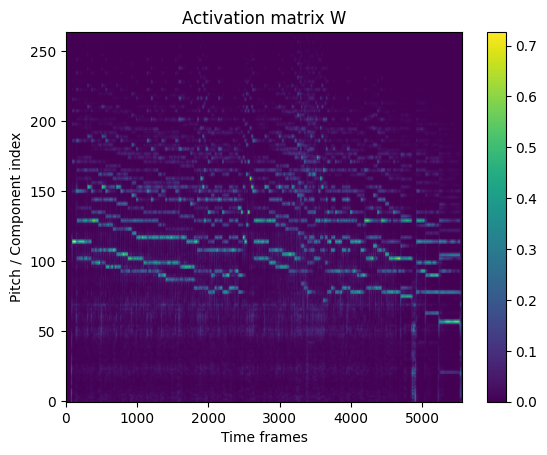

In [5]:
from scipy.io import wavfile
import librosa
import numpy as np
K = 3
HOP = 1024
file_name_string_audio = "Prelude-in-E-Minor-Nr-4.wav"
g = 2
f_s, x = wavfile.read(file_name_string_audio)
if(x.dtype==np.int32):
  x = x / (2**31)
elif(x.dtype==np.int16):
  x = x / (2**15)
else:
  raise ValueError(f"Unsupported sample type: {x.dtype}")
spectrogram = np.abs(librosa.cqt(x,sr=f_s, fmin=librosa.note_to_hz('A0'), bins_per_octave=12 * K, n_bins=88 * K, hop_length=HOP))
onsets = librosa.onset.onset_detect(y=x, sr=f_s, hop_length=HOP,units='frames')
K = 3
def norm_log(H, gamma=5):
    return np.log1p(gamma * H)
spectrogram = norm_log(spectrogram, g)
spectrogram = librosa.util.normalize(spectrogram, norm = 2, axis = 0, threshold = 0.05)

import matplotlib.pyplot as plt
plt.figure()
plt.imshow(spectrogram, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [166]:
import numpy as np

model = MinimumVolumeSparseNearSeparableNMF(
    rank=88,

    # Sparse activations
    lambda_h=1e-6,

    # Minimum-volume
    lambda_v=0.0,

    # Near-separability
    lambda_s=0,

    max_iter=100,
    h_inner_iter=2,
    w_inner_iter=3,

    candidate_count=512,
    anchor_update_period=5,

    normalize_input=True,
    random_state=42,
    tol=1e-5,
    verbose=True,
)

model.fit(spectrogram)

W = model.W
H = model.H

X_hat = model.reconstruct()

print(W.shape)  # (1024, 88)
print(H.shape)  # (88, 10000)
print(np.sum(W, axis=0))  # approximately all ones

/tmp/ipykernel_1684/1964080268.py:858: RuntimeWarning: invalid value encountered in scalar divide
  abs(previous_obj - obj)


iter=   1 obj=1.948849e+01 recon=1.948420e+01 H_L1=4.288437e+03 vol=-3.405901e+02 sep=5.718731e-02 rel=nan
iter=   2 obj=1.379351e+01 recon=1.378822e+01 H_L1=5.289323e+03 vol=-3.367581e+02 sep=1.120635e-01 rel=2.922e-01
iter=   3 obj=1.085263e+01 recon=1.084694e+01 H_L1=5.686952e+03 vol=-3.338250e+02 sep=1.639007e-01 rel=2.132e-01
iter=   4 obj=9.231161e+00 recon=9.225276e+00 H_L1=5.884969e+03 vol=-3.310689e+02 sep=2.125010e-01 rel=1.494e-01
iter=   5 obj=8.129713e+00 recon=8.123723e+00 H_L1=5.989788e+03 vol=-3.285048e+02 sep=2.596157e-01 rel=1.193e-01
iter=   6 obj=7.371097e+00 recon=7.365055e+00 H_L1=6.041121e+03 vol=-3.260631e+02 sep=2.711913e-01 rel=9.331e-02
iter=   7 obj=6.801971e+00 recon=6.795910e+00 H_L1=6.061666e+03 vol=-3.236666e+02 sep=3.104888e-01 rel=7.721e-02
iter=   8 obj=6.325083e+00 recon=6.319005e+00 H_L1=6.078005e+03 vol=-3.212043e+02 sep=3.494393e-01 rel=7.011e-02
iter=   9 obj=5.911106e+00 recon=5.905013e+00 H_L1=6.093207e+03 vol=-3.187237e+02 sep=3.871466e-01 rel

(264, 88)


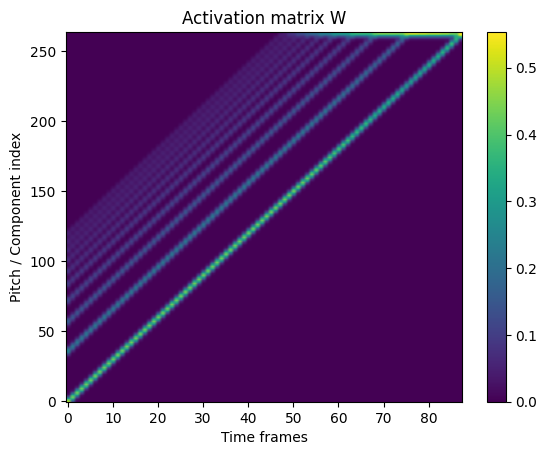

In [148]:
def build_W0(sr,
             bins_per_octave,
             n_bins,
             fmin,
             n_harmonics=10,
             decay=1.0,
             sigma=1.5,
             inharmonicity=0.0):

    # CQT frequency grid (MUST match your spectrogram)
    freqs = librosa.cqt_frequencies(
        n_bins=n_bins,
        fmin=fmin,
        bins_per_octave=bins_per_octave
    )

    midi_notes = np.arange(21, 21 + 88)  # piano
    W0 = np.zeros((n_bins, len(midi_notes)))

    for i, m in enumerate(midi_notes):
        f0 = librosa.midi_to_hz(m)
        template = np.zeros(n_bins)

        for h in range(1, n_harmonics + 1):
            # optional piano inharmonicity
            fh = h * f0 * np.sqrt(1 + inharmonicity * h**2)

            if fh >= sr / 2:
                break

            # nearest bin
            idx = np.argmin(np.abs(freqs - fh))

            # Gaussian spread
            k = np.arange(n_bins)
            peak = np.exp(-(k - idx)**2 / (2 * sigma**2))

            template += (1 / (h ** decay)) * peak

        # normalize (critical)
        template /= np.linalg.norm(template) + 1e-10

        W0[:, i] = template

    return W0

def build_noise_basis(n_bins, n_components=2):
    Wn = np.zeros((n_bins, n_components))

    for i in range(n_components):
        # random smooth noise shape
        x = np.random.rand(n_bins)
        x = np.convolve(x, np.hanning(15), mode='same')
        x /= np.linalg.norm(x) + 1e-10
        Wn[:, i] = x

    return Wn

W_0 = build_W0(sr=f_s, bins_per_octave=12*K, n_bins=88 * K, fmin=librosa.note_to_hz('A0'), sigma=2.0)
#Wn = build_noise_basis(88*K, 1)
#W_0 = np.concatenate([W_0, Wn], axis=1)

print(W_0.shape)
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(W_0, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [ ]:
print(spectrogram.shape)

(264, 5562)


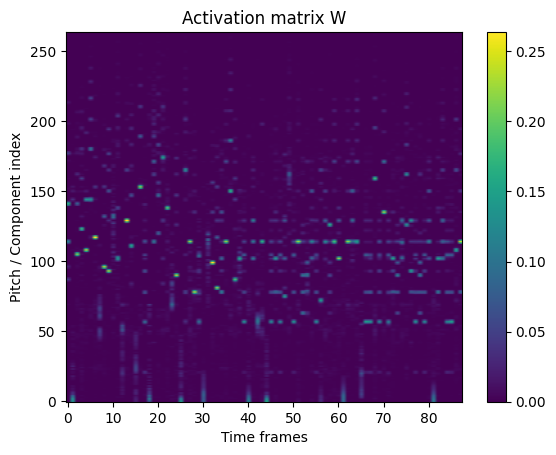

In [167]:
#W[262,:] = 0
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(W, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

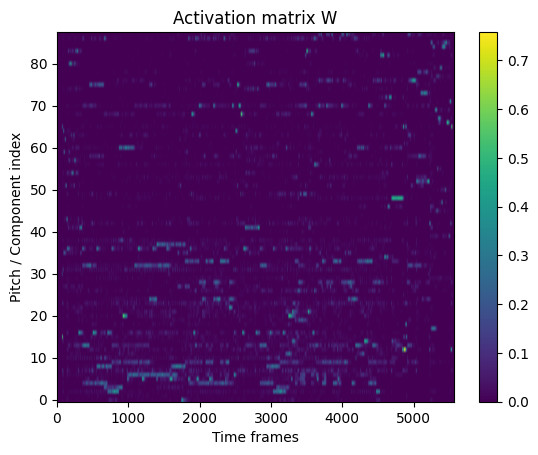

In [168]:
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(H, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [141]:
print(onsets)

[  87  140  152  181  233  255  278  300  325  353  384  407  430  453
  479  500  526  553  583  606  629  656  684  706  765  794  817  840
  895  920  983 1013 1037 1061 1087 1112 1135 1161 1191 1221 1244 1268
 1292 1318 1339 1364 1394 1420 1445 1467 1489 1512 1533 1567 1579 1591
 1616 1638 1688 1743 1767 1815 1838 1860 1884 1911 1934 1956 1986 2014
 2036 2058 2083 2134 2157 2188 2239 2283 2340 2358 2370 2411 2451 2478
 2501 2523 2544 2573 2596 2611 2631 2664 2687 2710 2733 2758 2784 2812
 2841 2869 2889 2911 2933 2956 2958 2979 2982 3001 3024 3026 3050 3072
 3095 3117 3162 3181 3201 3203 3229 3239 3250 3269 3272 3277 3283 3288
 3296 3314 3333 3355 3370 3382 3404 3428 3452 3472 3494 3516 3537 3560
 3580 3602 3623 3631 3641 3663 3689 3714 3744 3769 3800 3823 3845 3867
 3942 3953 3980 4007 4030 4077 4103 4130 4160 4181 4199 4231 4254 4279
 4305 4334 4360 4385 4418 4448 4472 4498 4525 4584 4620 4690 4909 5036
 5228]


In [ ]:
print(np.sum(H[88,:]))

0.008461577837033777


In [80]:
def compute_energy_for_pitch(fr, bs, coef):
  freq = [float(np.log2(i+2)*12*coef) for i in range(11)]
  #print(freq)
  K = 0
  r = 0
  for m in freq:
    #print(K)
    if(bs+int(m)>=88*coef-1):
      #print("out", bs+int(m))
      break
    r += 1
    #print(m)
    F = m % 1
    #print(F, bs+int(m))
    #print(fr[bs+int(m)])
    sm = (1-F) * fr[bs+int(m)] + F * fr[bs+int(m)+1]
    #print(sm)
    '''if(sm!=0):
      K += np.log(sm)'''
    if(sm!=0):
      K += sm
  if(r==0):
    return 0
  else:
    #print(K)
    return float(K/r)

In [119]:
print(onsets)

[  87  140  152  181  233  255  278  300  325  353  384  407  430  453
  479  500  526  553  583  606  629  656  684  706  765  794  817  840
  895  920  983 1013 1037 1061 1087 1112 1135 1161 1191 1221 1244 1268
 1292 1318 1339 1364 1394 1420 1445 1467 1489 1512 1533 1567 1579 1591
 1616 1638 1688 1743 1767 1815 1838 1860 1884 1911 1934 1956 1986 2014
 2036 2058 2083 2134 2157 2188 2239 2283 2340 2358 2370 2411 2451 2478
 2501 2523 2544 2573 2596 2611 2631 2664 2687 2710 2733 2758 2784 2812
 2841 2869 2889 2911 2933 2956 2958 2979 2982 3001 3024 3026 3050 3072
 3095 3117 3162 3181 3201 3203 3229 3239 3250 3269 3272 3277 3283 3288
 3296 3314 3333 3355 3370 3382 3404 3428 3452 3472 3494 3516 3537 3560
 3580 3602 3623 3631 3641 3663 3689 3714 3744 3769 3800 3823 3845 3867
 3942 3953 3980 4007 4030 4077 4103 4130 4160 4181 4199 4231 4254 4279
 4305 4334 4360 4385 4418 4448 4472 4498 4525 4584 4620 4690 4909 5036
 5228]


In [81]:
print(onsets)

[  87  140  152  181  233  255  278  300  325  353  384  407  430  453
  479  500  526  553  583  606  629  656  684  706  765  794  817  840
  895  920  983 1013 1037 1061 1087 1112 1135 1161 1191 1221 1244 1268
 1292 1318 1339 1364 1394 1420 1445 1467 1489 1512 1533 1567 1579 1591
 1616 1638 1688 1743 1767 1815 1838 1860 1884 1911 1934 1956 1986 2014
 2036 2058 2083 2134 2157 2188 2239 2283 2340 2358 2370 2411 2451 2478
 2501 2523 2544 2573 2596 2611 2631 2664 2687 2710 2733 2758 2784 2812
 2841 2869 2889 2911 2933 2956 2958 2979 2982 3001 3024 3026 3050 3072
 3095 3117 3162 3181 3201 3203 3229 3239 3250 3269 3272 3277 3283 3288
 3296 3314 3333 3355 3370 3382 3404 3428 3452 3472 3494 3516 3537 3560
 3580 3602 3623 3631 3641 3663 3689 3714 3744 3769 3800 3823 3845 3867
 3942 3953 3980 4007 4030 4077 4103 4130 4160 4181 4199 4231 4254 4279
 4305 4334 4360 4385 4418 4448 4472 4498 4525 4584 4620 4690 4909 5036
 5228]


In [82]:
print(H[:,87])

[0.00460417 0.00206935 0.0055971  0.0027727  0.00524928 0.00185416
 0.00357097 0.00679429 0.00412612 0.00444931 0.00587871 0.00406385
 0.         0.00062782 0.00241111 0.00202932 0.00375001 0.00281959
 0.         0.         0.00268573 0.00264688 0.         0.01070828
 0.0074565  0.00133797 0.000992   0.         0.         0.
 0.         0.         0.         0.00131603 0.01039431 0.00684218
 0.01446248 0.01324667 0.09593373 0.02644291 0.00510168 0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.00011478 0.00010811 0.
 0.         0.         0.         0.        ]


In [103]:
compute_energy_for_pitch(H[:,140],38,1)

0.003171179184063669

In [ ]:
print([float(np.log2(i+2)*36) for i in range(11)])
#print([i+2 for i in range(11)])

[36.0, 57.05865002596162, 72.0, 83.58941141594504, 93.05865002596161, 101.06477719407376, 108.0, 114.11730005192324, 119.58941141594504, 124.5395382709427, 129.0586500259616]


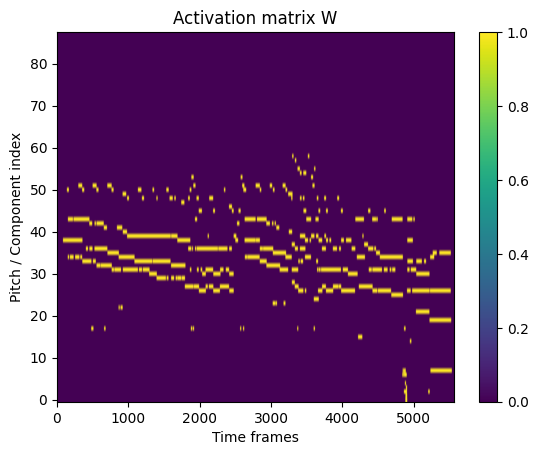

In [ ]:
import scipy
from scipy.ndimage import label
def med_filter(X, sz=5):
  X_r = np.zeros(X.shape)
  for i in range(X.shape[0]):
    X_r[i,:] = scipy.ndimage.median_filter(X[i,:], size=sz, cval=0, mode='constant')
  return X_r

def enforce_min_duration(B, min_len=10):
    for q in range(B.shape[0]):
        labels, n = label(B[q])
        for i in range(1, n+1):
            if np.sum(labels == i) < min_len:
                B[q][labels == i] = 0
    return B
H1 = med_filter(H)
H2 = np.zeros_like(H1)
idx = np.argpartition(H1, -17, axis=0)[-17:, :]
H2[idx, np.arange(H1.shape[1])] = H1[idx, np.arange(H1.shape[1])]
H3 = med_filter(H2)
t = H3.max() * 0.145
H4 = (H3 > t).astype(int)
H5 = enforce_min_duration(H4,min_len=15)
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(H5, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix W")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

In [ ]:
pip install pretty_midi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 30.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.6/54.6 kB 3.8 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pretty_midi

def midi_to_binary_matrix(
    midi_input,
    dt=0.02,                     # time quantum in seconds
    pitch_range=(21, 108),  # A0–C8 by default
    min_overlap=0.5         # fraction of frame that must be covered
):
    """
    Convert MIDI to binary (88 x T) note activation matrix using fixed time grid.

    A note is active in a frame if it overlaps the frame
    by at least min_overlap * dt.
    """

    if dt <= 0:
        raise ValueError("dt must be positive (seconds)")

    # Load MIDI
    if isinstance(midi_input, pretty_midi.PrettyMIDI):
        pm = midi_input
    else:
        pm = pretty_midi.PrettyMIDI(midi_input)

    # Time axis
    total_time = pm.get_end_time()
    T = int(np.ceil(total_time / dt))
    frame_times = np.arange(T) * dt

    n_pitches = pitch_range[1] - pitch_range[0] + 1
    B = np.zeros((n_pitches, T), dtype=np.uint8)

    # Process notes
    for instrument in pm.instruments:
        if instrument.is_drum:
            continue

        for note in instrument.notes:
            if not (pitch_range[0] <= note.pitch <= pitch_range[1]):
                continue

            p = note.pitch - pitch_range[0]

            start_frame = int(np.floor(note.start / dt))
            end_frame   = int(np.ceil(note.end   / dt))

            for t in range(start_frame, min(end_frame, T)):
                frame_start = t * dt
                frame_end   = frame_start + dt

                overlap = max(
                    0.0,
                    min(note.end, frame_end) - max(note.start, frame_start)
                )

                if overlap >= min_overlap * dt:
                    B[p, t] = 1

    return B, frame_times

(88, 5513) (89, 5562)


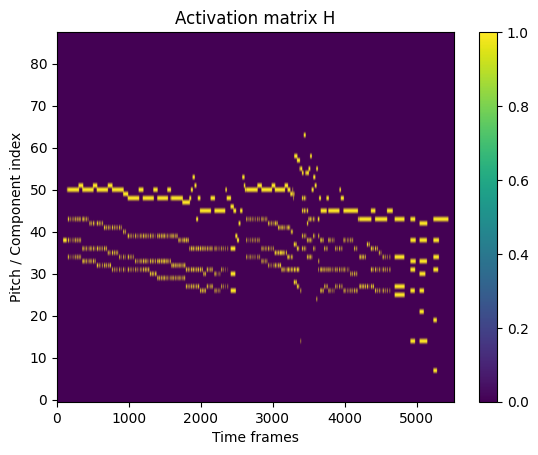

In [ ]:
# 20 ms frames (matches typical STFT hop ~512 @ 44.1kHz)
dt = 1024 / f_s
B, times = midi_to_binary_matrix(
    "Prelude-in-E-Minor-Nr-4.mid",
    dt=dt
)
print(B.shape,H4.shape)
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(B, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix H")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()

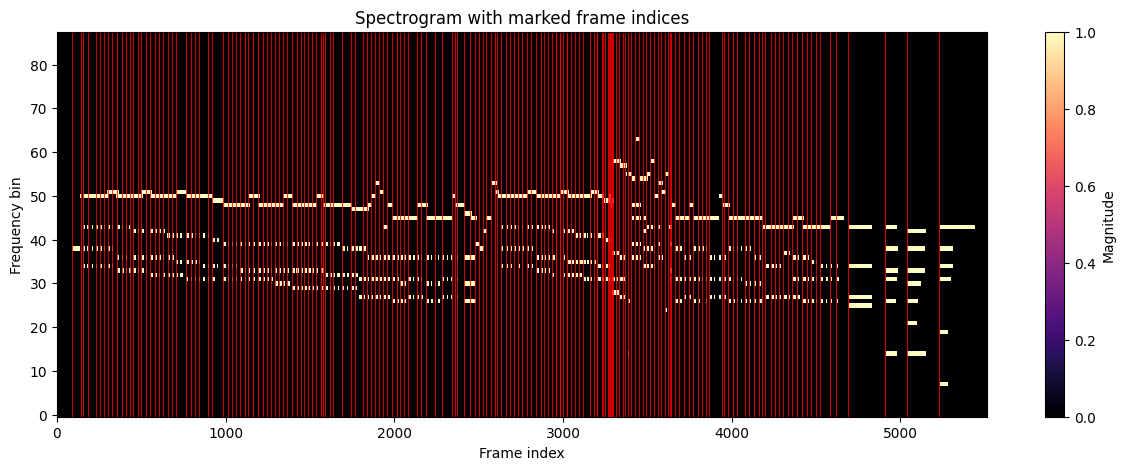

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
plt.imshow(B, aspect='auto', origin='lower', interpolation='nearest', cmap='magma')

for idx in onsets:
    plt.axvline(x=idx, color='red', linewidth=0.8, alpha=0.8)

plt.xlabel("Frame index")
plt.ylabel("Frequency bin")
plt.title("Spectrogram with marked frame indices")
plt.colorbar(label="Magnitude")
plt.show()

In [ ]:
def evaluate_results(H_et,H):
  #H_et - reference transcription of the piece
  #H - estimated transcription of the piece
  assert H_et.shape == H.shape
  P = 0
  R = 0
  F1 = 0
  TP = 0
  FP = 0
  FN = 0
  for i in range(H_et.shape[1]):
    TP += sum(1 for t, p in zip(H_et[:,i], H[:,i]) if t == 1 and p == 1)
    FP += sum(1 for t, p in zip(H_et[:,i], H[:,i]) if t == 0 and p == 1)
    FN += sum(1 for t, p in zip(H_et[:,i], H[:,i]) if t == 1 and p == 0)
  P = TP / (TP + FP)
  R = TP / (TP + FN)
  F1 = 2 * P * R / (P + R)
  return (P,R,F1)

In [ ]:
print(H5[:,:B.shape[1]].shape)
print(B.shape)

(89, 5513)
(88, 5513)


In [ ]:
print(evaluate_results(H5[:,:B.shape[1]],B))

(0.6483238456672992, 0.4698871124863905, 0.5448686002857238)


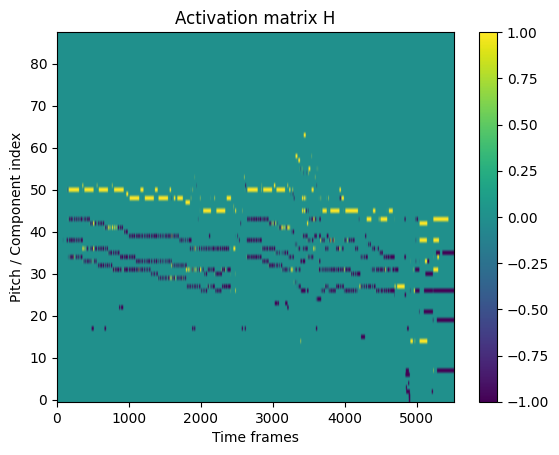

In [ ]:
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(B-H5[:,:B.shape[1]], aspect='auto', origin='lower')
plt.colorbar()
plt.title("Activation matrix H")
plt.xlabel("Time frames")
plt.ylabel("Pitch / Component index")
plt.show()